# DBA5106 Project 2 · Steel scratch triage

Can geometry and brightness measurements from surface inspection identify which already-flagged steel plate faults should receive priority scratch review?

**Decision.** A quality inspector routes high-scoring records to a scratch-specific review. Other flagged records remain in the ordinary defect queue. Define 1 as a confirmed `Z_Scratch` or `K_Scatch` label. The uploaded CSV uses the spelling `K_Scatch`.

**Evaluation loss.** $L=(5\,FN+FP)/n$. A missed priority scratch review costs five times an unnecessary priority review in this scenario. The ratio is a modeling assumption. We check 2:1 and 10:1 on validation as sensitivity cases.

**Source.** [Faulty Steel Plates, UCI Machine Learning on Kaggle](https://www.kaggle.com/datasets/uciml/faulty-steel-plates), usability 8.24/10. The separate wafer project supplied with this task informed the structure. All features and results below are from `data/faults.csv`.

The notebook uses `analysis.py` in the same folder. All sections can be rerun using **Restart Kernel and Run All**. The training cell runs a modest grid and can take about a minute or two on a CPU.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from analysis import analyze, load_data, make_splits

root = Path.cwd()
data = root / 'data' / 'faults.csv'
results = root / 'results'
x, y, subtype, audit = load_data(data)
print(f"{audit['rows']:,} records, {audit['positive']:,} scratches, {audit['negative']:,} other faults")
print(f"Missing cells: {audit['missing_cells']}. Duplicate rows after feature engineering: {audit['duplicate_feature_rows']}.")
display(pd.DataFrame({'fault label': list(audit['subtypes']), 'records': list(audit['subtypes'].values())}))

1,941 records, 581 scratches, 1,360 other faults
Missing cells: 0. Duplicate rows after feature engineering: 0.


,fault label,records
0,Other_Faults,673
1,Bumps,402
2,K_Scatch,391
3,Z_Scratch,190
4,Pastry,158
5,Stains,72
6,Dirtiness,55


## 1. Features and splits

Use 20 predictors involving geometry, brightness and plate properties. Compute width and height from bounding-box limits and calculate mean brightness as total brightness divided by defect area. Remove all seven label columns, absolute coordinates, conveyor length, the complementary grade indicator, and the logged area and dimensions. Absolute coordinates and conveyor identifiers can capture the inspection setup. The source provides limited definitions for some indices, so those labels are interpreted conservatively.

Split the records with label stratification. Fit the scaler inside training folds. Use five-fold CV within training for grid tuning and the separate validation partition for model, calibration and threshold decisions. Evaluate the locked policy on the held-out test partition. The source has no lot or line identifiers for a grouped split.

In [2]:
splits = make_splits(y)
display(pd.DataFrame({name: {'rows': len(rows), 'scratches': int(y.loc[rows].sum())}
                      for name, rows in splits.items()}).T)
print(', '.join(x.columns))

,rows,scratches
train,1164,349
validation,388,116
test,389,116


Pixels_Areas, X_Perimeter, Y_Perimeter, Minimum_of_Luminosity, Maximum_of_Luminosity, TypeOfSteel_A300, Steel_Plate_Thickness, Edges_Index, Empty_Index, Square_Index, Outside_X_Index, Edges_X_Index, Edges_Y_Index, Outside_Global_Index, Orientation_Index, Luminosity_Index, SigmoidOfAreas, Width_px, Height_px, Mean_Luminosity


## 2. Four models, separately tuned

The glass-box structure is a linear predictor with L1 regularization. Its two versions minimize squared error on 0/1 or binomial log loss. The black-box structure is a gradient-boosted tree ensemble, with squared error or binomial log loss. L1 here refers to a coefficient penalty. L2 refers to squared prediction error. All four configurations are tuned independently on CV AUC.

AUC uses the original ordered scores, including squared-loss outputs outside [0, 1]. For the reliability and Brier comparison, clip squared-loss outputs to [0, 1] or compare against sigmoid-calibrated versions. Select the highest validation AUC before testing.

In [3]:
s = analyze(data, results)
models = pd.DataFrame(s['models']).set_index('model')
display(models[['cv_auc', 'train_auc', 'validation_auc', 'parameters']].round(4))
print(f"Highest training-only single-feature AUC: {max(s['single_feature_screen'].values()):.3f}.")

Loaded 1941 records and 20 features. Tuning the four models…
                   model   cv_auc  validation_auc  raw_brier  platt_brier
Boosted trees / Log loss 0.975689        0.970335   0.057254     0.056426
      Boosted trees / L2 0.971265        0.966468   0.063012     0.059918
       Linear / Log loss 0.932641        0.907264   0.097551     0.108170
             Linear / L2 0.908926        0.863876   0.120049     0.119622
Selected Boosted trees / Log loss. Locked Platt policy at 0.162645.
Held-out AUC 0.9836
              threshold     tn     fp     fn     tp  reviewed  weighted_loss  weighted_errors  review_rate  recall  precision  accuracy
Review none      1.0000  273.0    0.0  116.0    0.0       0.0         1.4910            580.0       0.0000  0.0000     0.0000    0.7018
Review all       0.0000    0.0  273.0    0.0  116.0     389.0         0.7018            273.0       1.0000  1.0000     0.2982    0.2982
Default 0.50     0.5000  261.0   12.0   12.0  104.0     116.0         0.1

,cv_auc,train_auc,validation_auc,parameters
model,,,,
Boosted trees / Log loss,0.9757,0.9986,0.9703,"{'max_depth': 3, 'min_samples_leaf': 15, 'n_estimators': 240}"
Boosted trees / L2,0.9713,0.9968,0.9665,"{'max_depth': 3, 'min_samples_leaf': 15, 'n_estimators': 240}"
Linear / Log loss,0.9326,0.9434,0.9073,{'logisticregression__C': 10}
Linear / L2,0.9089,0.9157,0.8639,{'lasso__alpha': 0.0003}


Highest training-only single-feature AUC: 0.834.


## 3. Calibration and decision threshold

Fit Platt scaling on out-of-fold training scores. Compare raw and Platt Brier scores on validation, where a lower score is preferred. Also report ten-bin ECE and an eight-quantile-bin reliability plot for the chosen model. For the deployed probability form, search all distinct validation decisions for the minimum asymmetric loss. Use the less review-intensive policy when losses tie. A threshold of $1/(5+1)$ is the theoretical cost cutoff for calibrated deployment probabilities with this cost model.

,raw_brier,platt_brier,raw_ece,platt_ece,outside_unit_interval
model,,,,,
Boosted trees / Log loss,0.0573,0.0564,0.0257,0.0280,0
Boosted trees / L2,0.0630,0.0599,0.0450,0.0232,103
Linear / Log loss,0.0976,0.1082,0.0343,0.0720,0
Linear / L2,0.1200,0.1196,0.0258,0.0441,71


Locked policy: Boosted trees / Log loss, Platt, cutoff 0.162645.


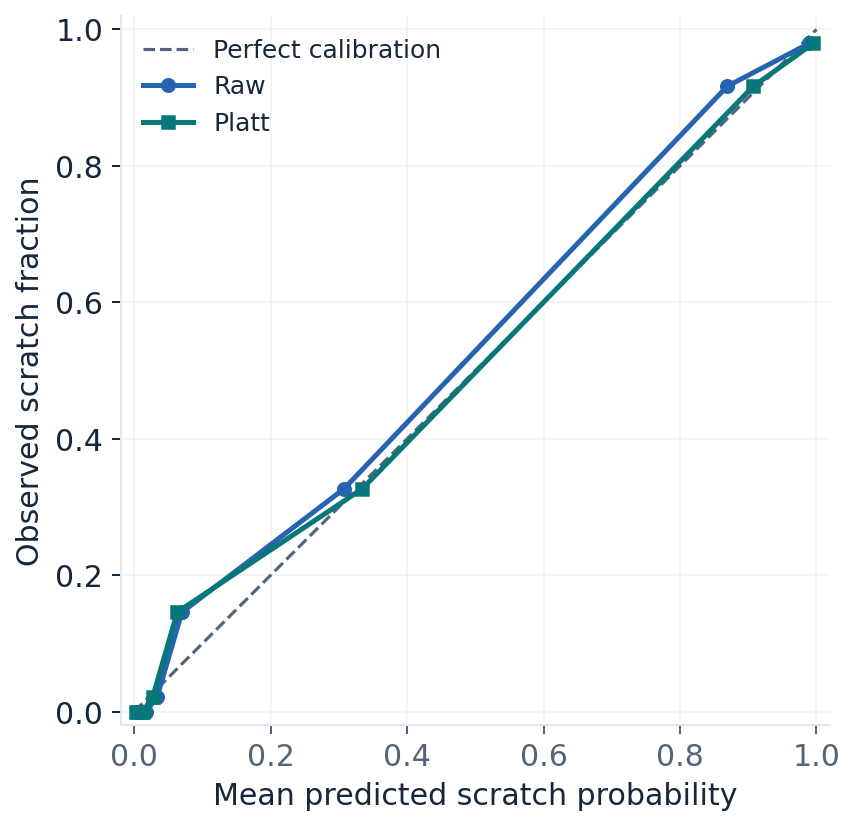

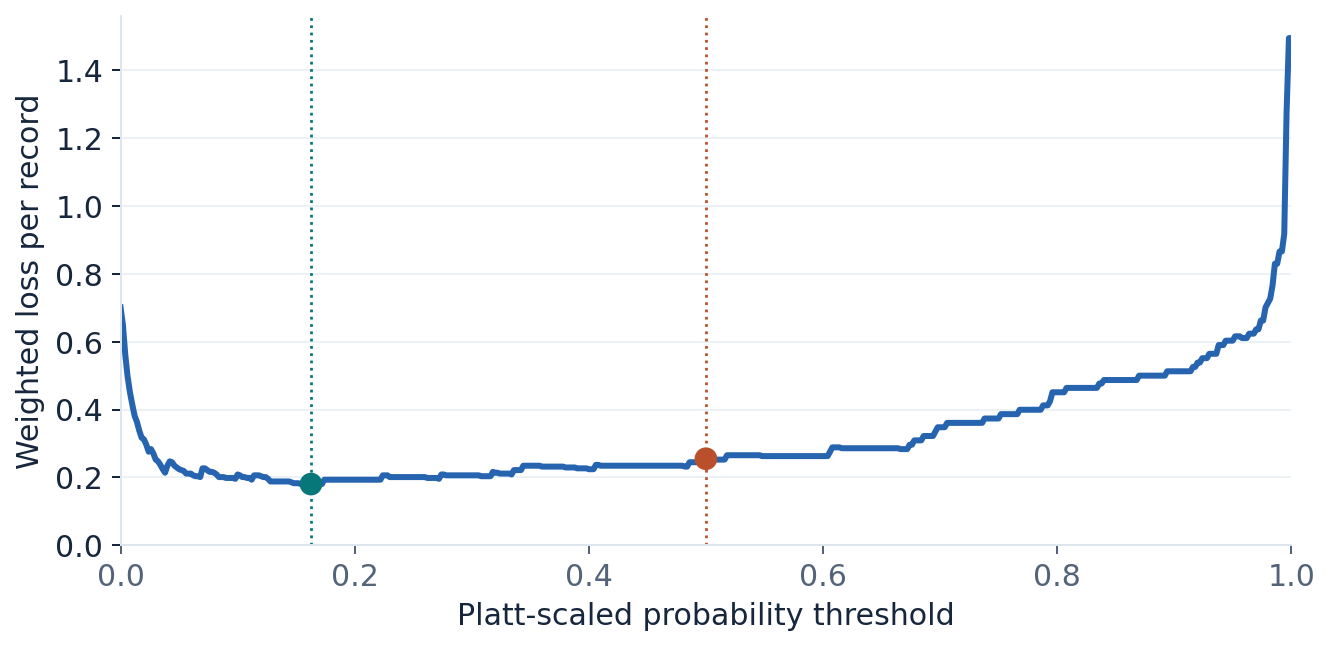

,reviewed,fn,fp,weighted_loss,recall
Review none,0.0,116.0,0.0,1.4948,0.0000
Review all,388.0,0.0,272.0,0.7010,1.0000
Default 0.50,107.0,18.0,9.0,0.2552,0.8448
Tuned rule,132.0,9.0,25.0,0.1804,0.9224


,cost_fn,threshold,review_rate,fn,fp,weighted_loss
0,2,0.4829,0.2835,16,10,0.1082
1,5,0.1626,0.3402,9,25,0.1804
2,10,0.0381,0.4974,1,78,0.2268


In [4]:
display(models[['raw_brier', 'platt_brier', 'raw_ece', 'platt_ece', 'outside_unit_interval']].round(4))
print(f"Locked policy: {s['model_selected']}, {s['calibration_selected']}, cutoff {s['threshold']:.6f}.")
for plot in ['calibration.png', 'threshold.png']:
    display(Image(filename=str(results / 'figures' / plot)))
display(pd.DataFrame(s['validation_decisions']).T[['reviewed', 'fn', 'fp', 'weighted_loss', 'recall']].round(4))
display(pd.DataFrame(s['validation_sensitivity'])[['cost_fn', 'threshold', 'review_rate', 'fn', 'fp', 'weighted_loss']].round(4))

## 4. Global and local TreeSHAP

Explain the tree ensemble with highest validation AUC. The code computes exact tree-path-dependent Shapley values by enumerating each shallow tree's feature coalitions. Unknown splits average child expectations using their training cover, and the feature contributions add to the raw ensemble output. The global plot aggregates mean absolute attribution across validation records. The local plot explains a validation case selected by a fixed rule that prioritizes false negatives. Correlated measurements can share the score contributions. Attributions describe the model and do not establish the cause of a scratch.

Row 161 (Z_Scratch), probability 0.113, reviewed False.
Expected raw score -1.813. Case raw score -2.021. Maximum additivity residual 8.44e-15.


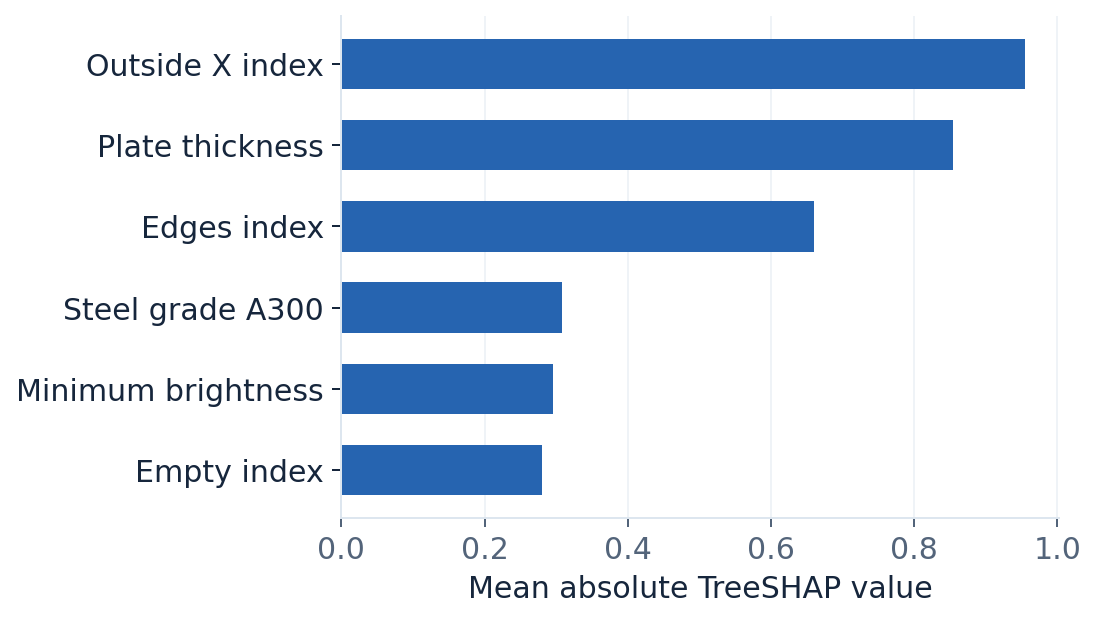

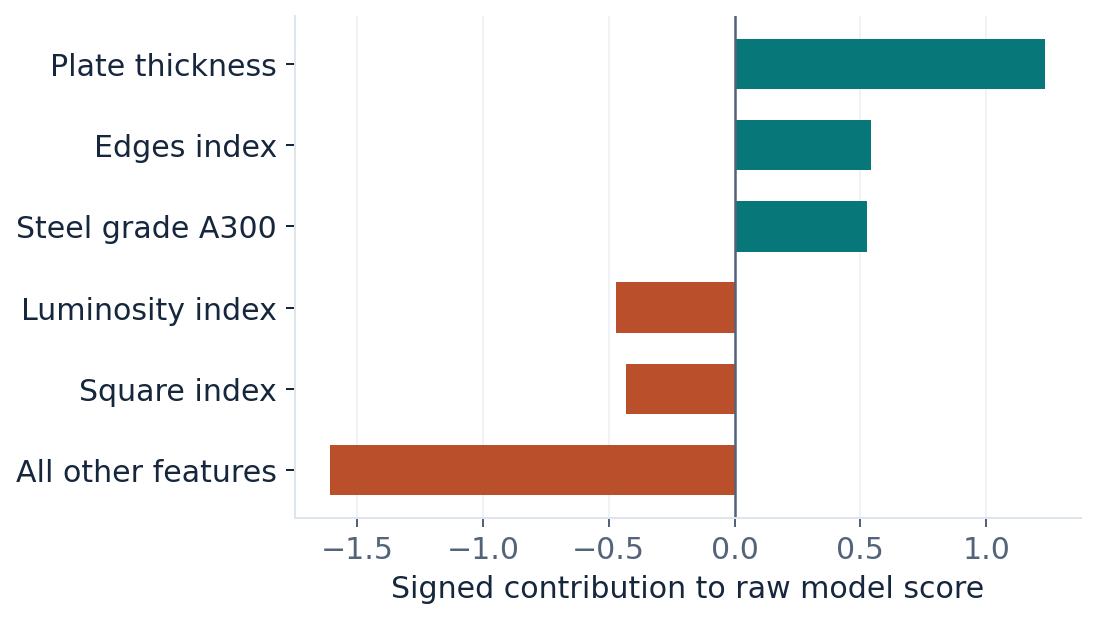

,value,shap
feature,,
Steel_Plate_Thickness,70.0000,1.2352
Edges_Index,0.0576,0.5409
TypeOfSteel_A300,1.0000,0.5244
Luminosity_Index,-0.3004,-0.4723
Square_Index,0.2143,-0.4299
Mean_Luminosity,89.5482,-0.4115


Validation AUC with thickness and grade removed: 0.9181. Same tree configuration.


In [5]:
shap = s['shap']
print(f"Row {shap['case_row_id']} ({shap['case_subtype']}), probability {shap['case_probability']:.3f}, reviewed {shap['case_reviewed']}.")
print(f"Expected raw score {shap['base']:.3f}. Case raw score {shap['case_score']:.3f}. Maximum additivity residual {shap['max_additivity_error']:.2e}.")
for plot in ['shap_global.png', 'shap_local.png']:
    display(Image(filename=str(results / 'figures' / plot)))
local = pd.read_csv(results / 'local_tree_shap.csv', index_col='feature')
display(local.loc[local['shap'].abs().nlargest(6).index].round(4))
print(f"Validation AUC with thickness and grade removed: {s['validation_auc_without_plate_context']:.4f}. Same tree configuration.")

## 5. Held-out results and interpretation

The test partition estimates the locked policy on comparable records from the same source. The paired bootstrap interval for improvement uses the same resampled test records under both rules. It represents sampling uncertainty conditional on the trained model and chosen cutoff. Real plant adoption would require a prospective lot- or time-separated evaluation and a measured review cost.

In [6]:
test = s['test']
print(f"Test AUC {test['auc']:.4f} with 95% bootstrap interval {tuple(round(v, 4) for v in test['bootstrap_95']['auc'])}.")
print(f"Test calibration Brier: raw {test['raw_calibration']['brier']:.4f}, Platt {test['platt_calibration']['brier']:.4f}.")
display(pd.DataFrame(test['policies']).T[['reviewed', 'fn', 'fp', 'weighted_loss', 'recall', 'precision']].round(4))
print('Paired 95% bootstrap intervals', test['bootstrap_95'])

Test AUC 0.9836 with 95% bootstrap interval (np.float64(0.9721), np.float64(0.9931)).
Test calibration Brier: raw 0.0454, Platt 0.0445.


,reviewed,fn,fp,weighted_loss,recall,precision
Review none,0.0,116.0,0.0,1.4910,0.0000,0.0000
Review all,389.0,0.0,273.0,0.7018,1.0000,0.2982
Default 0.50,116.0,12.0,12.0,0.1851,0.8966,0.8966
Tuned rule,145.0,3.0,32.0,0.1208,0.9741,0.7793


Paired 95% bootstrap intervals {'auc': [np.float64(0.9721158113177428), np.float64(0.9930927638945074)], 'cost': [np.float64(0.07197943444730077), np.float64(0.17744215938303307)], 'saving_vs_default': [np.float64(-0.010282776349614395), np.float64(0.14910025706940874)]}
